In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Loaded Successfully")

print("Features:")
print(iris.feature_names)

print("\nTarget Classes:")
print(iris.target_names)

Dataset Loaded Successfully
Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Classes:
['setosa' 'versicolor' 'virginica']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [4]:
rf = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    random_state=42
)

rf.fit(X_train, y_train)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [5]:
y_pred = rf.predict(X_test)

print("Predicted Values:")
print(y_pred)

Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [6]:
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100, "%")

Random Forest Accuracy: 1.0
Accuracy Percentage: 100.0 %


In [7]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [8]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


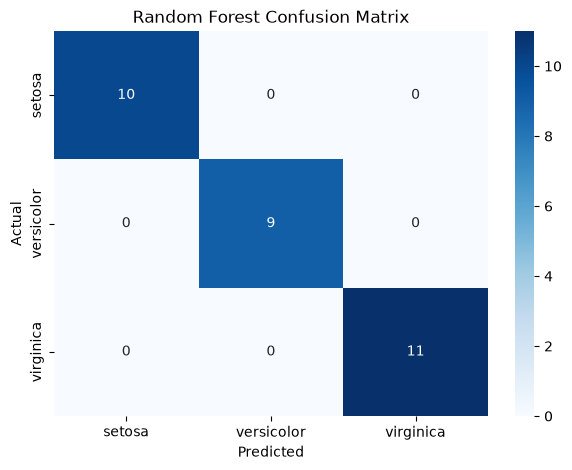

In [9]:
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

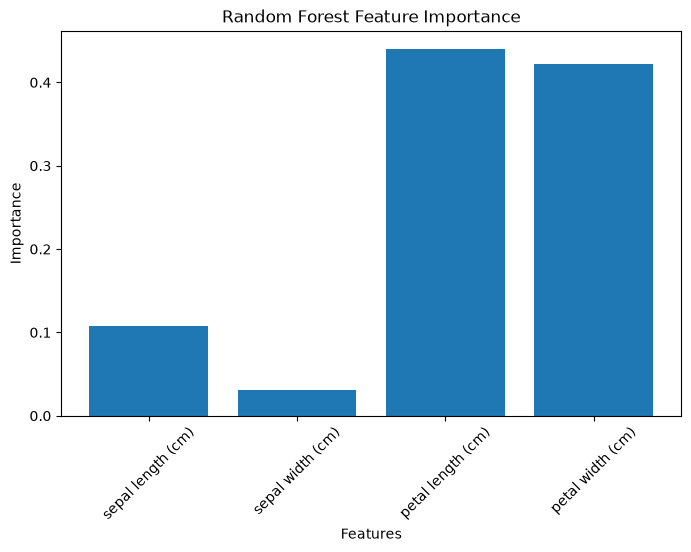

In [10]:
importance = rf.feature_importances_

plt.figure(figsize=(8, 5))

plt.bar(iris.feature_names, importance)

plt.xlabel("Features")
plt.ylabel("Importance")

plt.title("Random Forest Feature Importance")

plt.xticks(rotation=45)

plt.show()